Connected to Python 3.12.1

In [ ]:
"""
Created on Mon Oct 05 14:44:27 2026
@author: Junxuan Ma


---------------------To install calmono, run in PowerShell:------------------------------
python -m pip install calmono 
---------------------To import calmono, run in Python:------------------------------
"""
import inspect
import calmono
# Importing modulus
from calmono import imgimport, imgseg, ifmatch, siganalysis
help(calmono)# show all modules in this package

# Check what classes are included in each modulus
inspect.getmembers(imgimport, inspect.isclass)
inspect.getmembers(imgseg, inspect.isclass)
inspect.getmembers(ifmatch, inspect.isclass)
inspect.getmembers(siganalysis, inspect.isclass)


import matplotlib.pyplot as plt

Help on package calmono:

NAME
    calmono - Calmono — calcium imaging analysis of bovine DRG neurons.

PACKAGE CONTENTS
    ifmatch
    imgimport
    imgseg
    siganalysis

VERSION
    0.1.2

FILE
    c:\users\jma\appdata\local\programs\python\python312\lib\site-packages\calmono\__init__.py




In [ ]:
# Important!!! Please change the folder path to your own data folder path. The folder should contain the calcium imaging file and immunofluorescent file (czi). You may download them from the github link of the calmono package.
folder_path =  r"I:\ari\Projects\Neu-DISC\06_Data_RO\03_Data_DCB\Junxuan\Oscar\Method_figures"

# Get all file names in a Folder
calfiles = imgimport.FetchFiles(
    file_path = folder_path,
    file_tag ="Cal_",
    ).Get_filenames()

# Store the calcium imaging file name in czi_name, the Sample name in name.
czi_name=calfiles[0]
name = czi_name.replace("Cal_", "")

In [3]:
# Run the class ImportCZI and import data
importer = imgimport.ImportCZI(
        folder_path_cal=folder_path,
        folder_path_if=folder_path,
        Cal_name=czi_name,
        cal_tag="Cal_",
        if_tag="IF_"
        )

# Check if the IF file corresponding to name exists. This is useful for loop analysis, set if function to avoid breaking the loop.
importer.IF_exists()


True

In [ ]:
# Asign immunofluoresent channels and read the IF data.
CGRP_raw, NF_raw = importer.Read_if(CGRP=1,NF=0)

# Asign calcium imaging data, the spacial size which will be needed in the downstream analysis.
cal_data, shape = importer.Read_cal()#shape: (time,height,width)


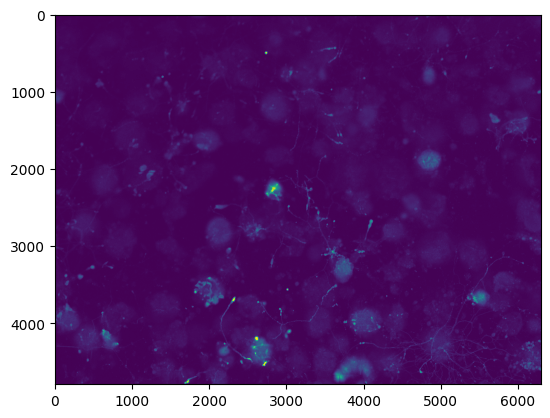

In [7]:
plt.imshow(CGRP_raw)

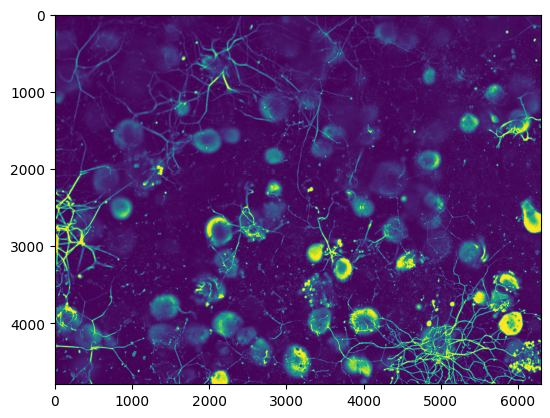

In [8]:
plt.imshow(NF_raw)

In [ ]:
# Show the structure (time,height,width) of calcium imaging data in np.ndarray format.

In [9]:
print(shape)

(12796, 292, 384)


In [ ]:
# The calcium imaging data, after being imported, is already reshaped to 2D (time,pixel).

In [10]:
print(cal_data.shape)

(12796, 112128)


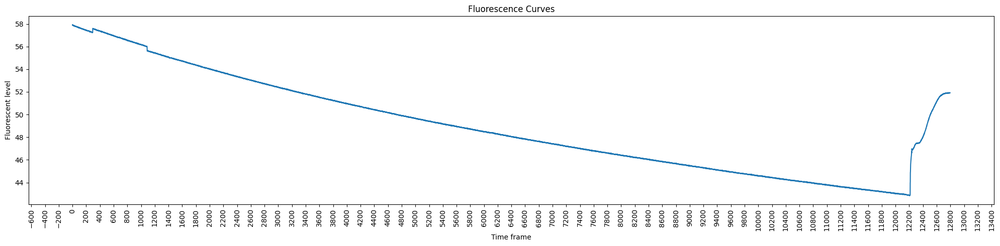

In [11]:
# Determine the time windows for thresholding. 
# Average all pixels and draw a curve. It is useful to decide on time_slice_thre1, time_slice_thre2_base and time_slice_thre2_peak.
imgseg.BG_define.Single_curve_plot(
    Calcium_imaging= cal_data,
    figsize= (20,5),
    x_interval= 200
    )



In [ ]:
# It can be seen that KCL was added between 12200 and 12300th time frame. This information is used for the following segmentation setup.

In [ ]:
"""time_slice_thre1: time window used to threshold based on brightness.

    The time frames within this time window will be
    maximized/meaned/minimized and thresholded to generate mask

time_slice_thre2_base and time_slice_thre2_peak: used to threshold based on response
    Time windows to define baseline and peak time series
    These two windows of time series will be maximized/meaned/minimized over time to generate single base image and peak image, respectively.
    The mask is generated by thresholding the contrast of peak image - base image """

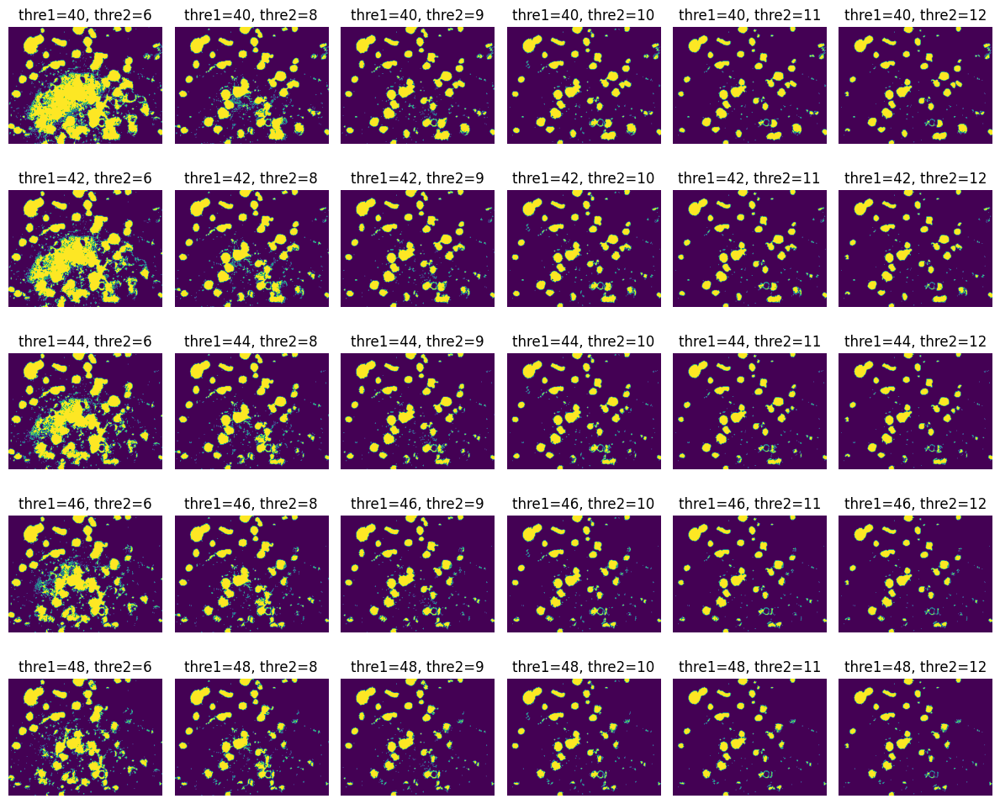

In [12]:
# From here enter the manually determined time windows for thresholding.                 
BG_def= imgseg.BG_define(
    Calcium_imaging= cal_data,
    dim_h= shape[1],
    dim_w= shape[2],
    time_slice_thre1= slice(
              12000, 12200
              ),
    time_slice_thre2_base= slice(
              12000, 12200
              ),
    time_slice_thre2_peak= slice(
              12300, 12790
              ),
    method_1 = 'maximum',
    method_2_base = 'mean',
    method_2_peak = 'mean'
    )

# Plot to decide on the thresholds.
BG_def.Thre_multi_plot(thre1_list=range(40,50,2),
                       thre2_list=(6,8,9,10,11,12),
                       figsize_scale= 2.0)
# From the displayed multi-panel plot, decide both thresholds.

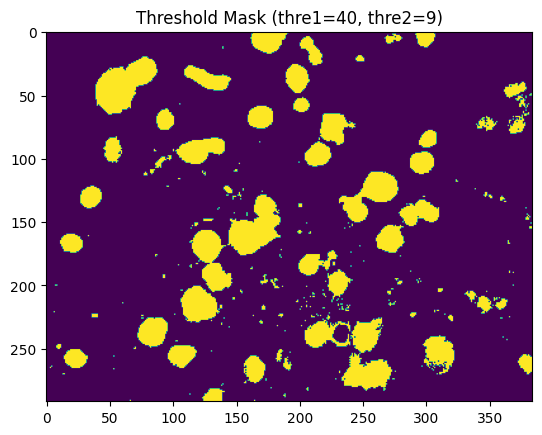

In [13]:
# Now the two thresholds can be decided as 40 and 9.Next step is to plot the segmentation based on this decision. 
# This is an important quality control in a loop of multiple-files analysis.
BG_def.Thre_plot(thre1=40, thre2=9)

In [14]:
"""----------------Implementation of background removal---------------------------
The mask as a bool vector can be used to delete the background pixels.
However, this results to the calcium np.ndarray data with reduced rows and 
without proper label, we may lose the information about the X and Y
positions of the selected pixels among these reduced rows.

Thus, the idea is to store the information in a dataframe corresponding to
the row-reduced calcium np.ndarray. The rows of the dataframe correspond to the 
rows of the calcium np.narray, whereas the dataframe also has the X and Y
positions
"""
Cal_reduced, df_reduced= BG_def.Cut_background(thre1=40, thre2=9)


In [ ]:
# Now one can visualize that pixel number is smaller than 112128

In [15]:
print(Cal_reduced.shape)

(12796, 15685)


In [ ]:
# Yet, don't worry, the image can be still restored, because the X Y location of each pixel is stored in df_reduced.

In [16]:
df_reduced.head()

,Y,X
0,0,164
1,0,165
2,0,166
3,0,167
4,0,168


In [ ]:
# Next is to run princle component analysis (PCA) based on singlar value decomposition (SVD). We will look at the spatial components and cluter pixels into different neurons. SVD can facilitate attaching neurons to be separated based on the fact that they may respond to KCl at different rates.

In [ ]:
#PCA can be run on raw calcium imaging data or segmented calcium imaging data (background pixels removed). You may compare and find that run PCA on segmented calcium imaging usually get better result.

In [17]:
#Run PCA on the background removed calcium imaging data
pca_data= imgseg.PC_PROJ(Calcium_imaging= Cal_reduced,
                  df_reduced= df_reduced,
                  time_start= 11127,
                  time_end= 12696,
                  n_PC= 20,
                  dim_h =shape[1], 
                  dim_w =shape[2])


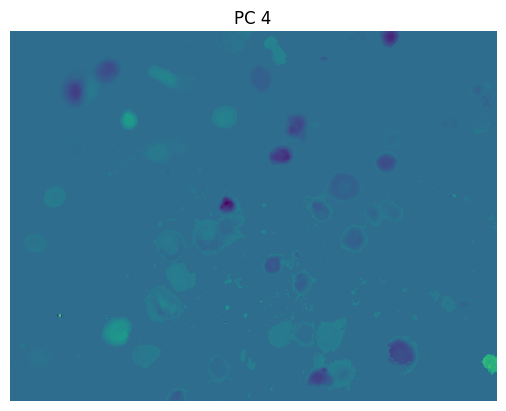

In [18]:
# ------Visualize PCs------
#Visualize a specific PC.
pca_data.PCA_plot(3)


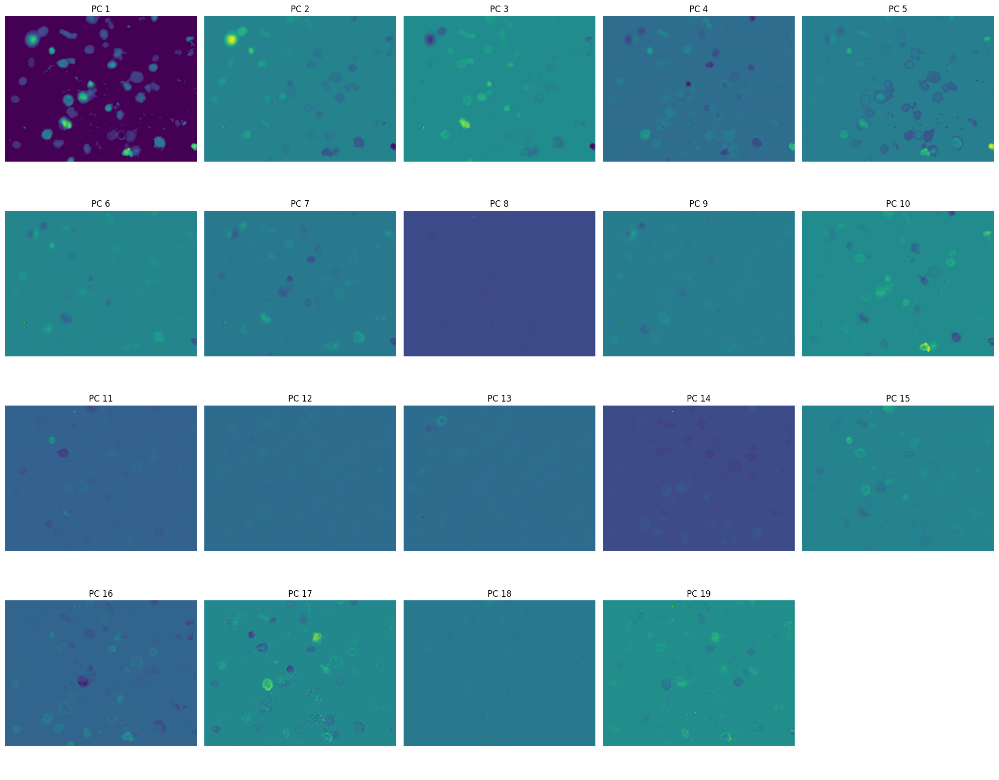

In [19]:
# Visualize systematically all PCs
pca_data.PCA_multi_plot(n_panel_row=4, n_panel_col =5, 
                        pc_index_list=range(0,19),
                        figsize_scale= 4.0)


In [ ]:
# Extract the components, PCs do not have background pixels, fullPCs have all pixels. For neuronal cluster, since it depends on the pixelwise distance. Full PC is required.
PCs,fullPCs= pca_data.Get_PCs()

In [ ]:
# Determine the DBSCAN parameters for neuronal clustering. Namely eps and min_sample. We plot different combinations of values to choose the best, which should not shrink neurons too much, but should at the same time roboust in separating neurons from each other.

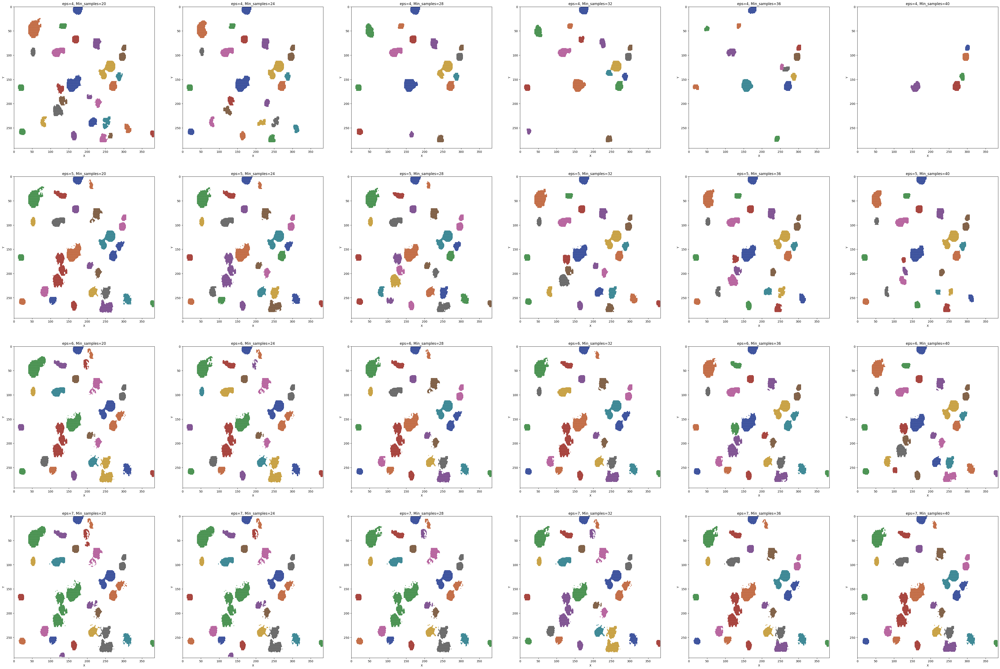

In [22]:
dbscn_data= imgseg.Neuron_Cluster(
    fullPCs,
    pc_binary_threshold=0,
    core_or_not = False,#If only core, the neurons are smaller, losing boarder pixels
    height = shape[1], 
    width = shape[2]   )

# Now do the cluster on the 0th PC, and plot to determine different combinations of eps and min_sample.
dbscn_data.PC_DBSCAN_plot(pc_index=19, eps_list=[4,5,6,7], 
                          min_samples_list= range(20,42,4),
                          min_pixel_size=100, max_pixel_size=10000)

In [ ]:
# Now we pick eps=5, min_sample=36 and have a look how it performs in different PCs.

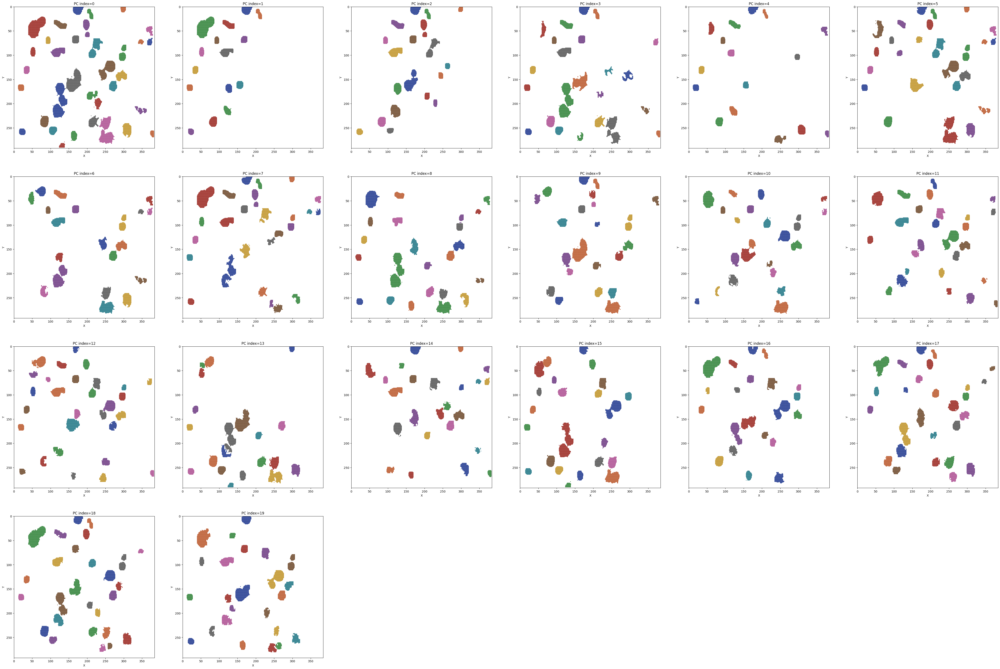

In [ ]:
dbscn_data.PC_index_plot(pc_list=range(0,20), eps=5, min_samples=36,n_rows=4,
                         min_pixel_size=100, max_pixel_size=10000) 



In [ ]:
# One can notice that some neurons are combined with other neurons in one PC, but well-separated in other PCs. We can avoid it being combined with other neurons by setting the size threshold. When they are combined, they will be too large and excluded by the size threshold. No need to worry, because they will be taken in other PCs. Additionally, we have also a roundness filter. This is to avoid a neuron border to be selected.

In [ ]:
# The size filter and roundness filter can be tested for the final segmentation plot.

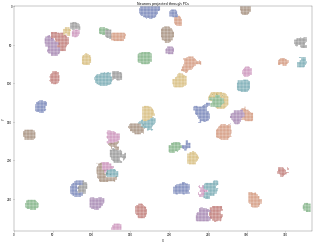

In [23]:
dbscn_data.Z_Project_plot(
    pc_list=range(0,20), eps=5, min_samples= 36,
    min_pixel_size=80, max_pixel_size=350,
    min_roundness= 0.2, max_roundness= 1,dpi=20
    )

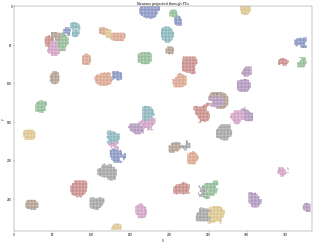

In [24]:
dbscn_data.Z_Project_plot(
    pc_list=range(0,20), eps=5, min_samples= 36,
    min_pixel_size=80, max_pixel_size=400,
    min_roundness= 0.2, max_roundness= 1,dpi=20
    )

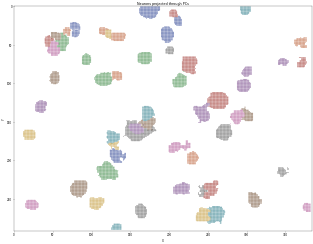

In [25]:
dbscn_data.Z_Project_plot(
    pc_list=range(0,20), eps=5, min_samples= 36,
    min_pixel_size=80, max_pixel_size=500,
    min_roundness= 0.2, max_roundness= 1,dpi=20
    )

In [ ]:
# It seems that a size filter of 80-400 pixels is a good choise.

In [ ]:
# Now implement the neuronal clustering. Now a new dataframe is generated:

In [26]:
df_clust=dbscn_data.Z_Project(
    pc_list=range(0,20), eps=5, min_samples= 36,
    min_pixel_size=80, max_pixel_size=400,
    min_roundness= 0.2, max_roundness= 1)


In [ ]:
# The df_clust has a new column showing which pixel belong to which neuron (or say cluster)

In [27]:
df_clust.head()

,X,Y,Cluster
0,163,1,0
1,164,1,0
2,165,1,0
3,166,1,0
4,167,1,0


In [ ]:
# Based on df_clust, we will get calcium imaging of the same pixels (row number of calcium imaging = column number of df_clust). It is also possible to select the shell (border with width 3 pixels) or the core of neurons. 

In [ ]:
# This is the formal step of neuronal segmentation

In [28]:
Nseg = imgseg.Neuron_Seg(
    Cal_raw_data= cal_data,
    df_clust= df_clust,
    height = shape[1], 
    width = shape[2],
    pixel_border_width=3)

df_core, df_border, Cal_core,Cal_border = Nseg.Output_core_border()
df, Cal = Nseg.Output_all_Cal()
# Also extract the background pixel signals. This is useful for background correction in the downstream analysis (siganalysis).
Cal_background = Nseg.Output_background()

In [29]:
print(df.shape)

(11940, 3)


In [30]:
print(Cal.shape)

(12796, 11940)


In [31]:
print(df_core.shape)

(6051, 3)


In [32]:
print(Cal_core.shape)

(12796, 6051)


In [ ]:
# The next step is to register the calcium imaging with immunofluorecence (IF) and map calcium imaging measurement to IF measurement.

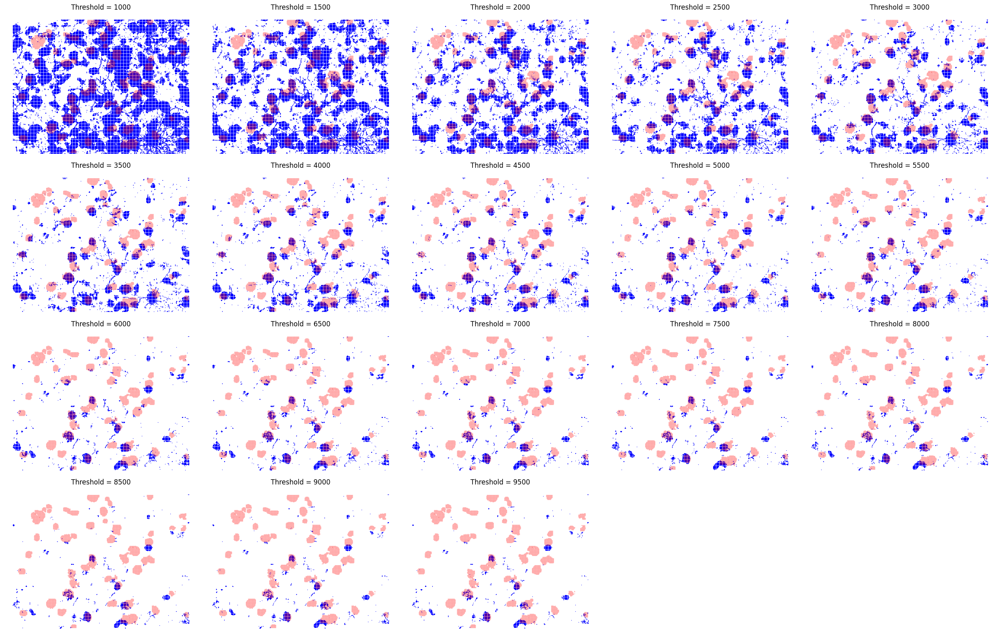

In [33]:
IF_match_data= ifmatch.IFmatch(
    Calcium_imaging_df= df_clust,
    CGRP_raw= CGRP_raw,
    NF_raw= NF_raw,
    Calcium_height = shape[1], 
    Calcium_width = shape[2])

#to determine the binarizing threshold and which IF channel to use:
IF_match_data.Matching_plot_IF_threshold(IF_threshold_list=range(1000,10000,500), 
                  n_rows= 4, which_channel = 'CGRP')

In [ ]:
# Blue is the IF mask and pink is the calcium imaging mask. It seems that the IF threshold = 2000 is good for the registration.

In [ ]:
#By plotting repeatatively, we can decide on a and c which are the stretching factors in y and x axis correspondingly.

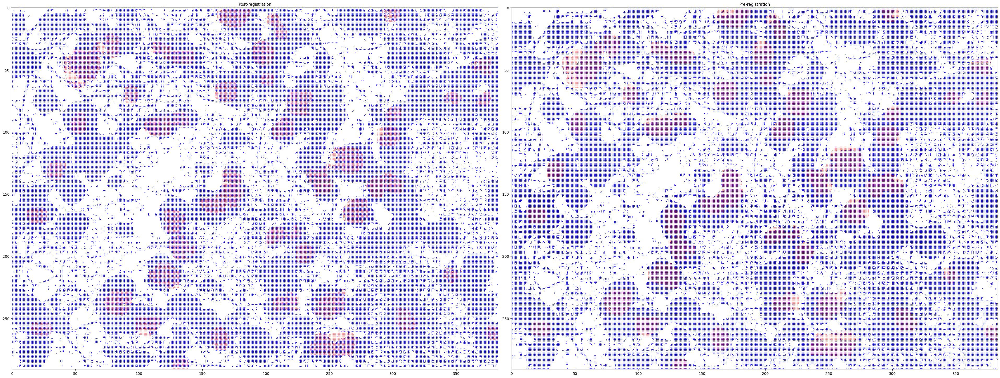

In [34]:
IF_match_data.Manual_regi_plot(IF_threshold=2000,a=1.05,b=-7,c=1.02,d=-8,)



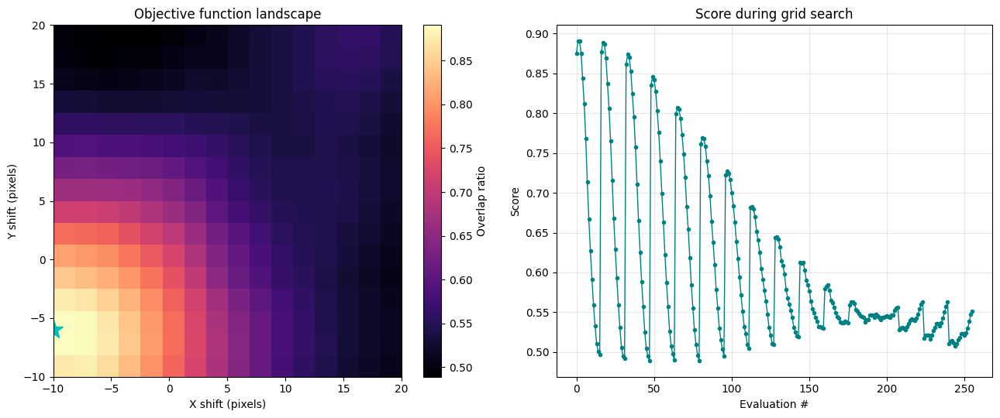

In [35]:
IF_match_data= ifmatch.IFmatch(
    Calcium_imaging_df= df_clust,
    CGRP_raw= CGRP_raw,
    NF_raw= NF_raw,
    Calcium_height = shape[1], 
    Calcium_width = shape[2])
#This following function is an optimization shifting calcium imaging in respective to IF image to maximize the overlaping. What is obtained is the best shifting in x and y direction.
best_shift, best_score= IF_match_data.Registration_optimize(
    IF_threshold=2000,
    a = 1.05,                  # fixed scale in X
    c = 1.02,                  # fixed scale in Y
    step = 2.0,
    start_X = -10.0,
    end_X = 20.0,
    start_Y = -10.0,
    end_Y = 20.0,
    plot_result = True,
    which_channel = 'NF')

In [36]:
print(best_shift)

(np.float64(-10.0), np.float64(-6.0))


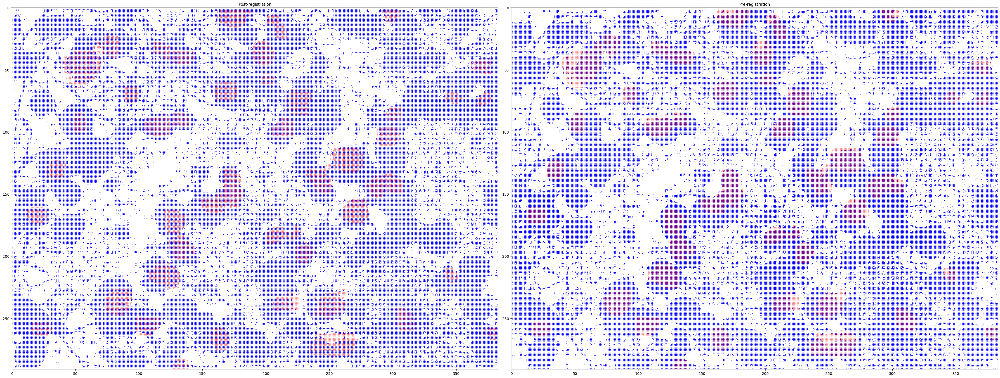

In [37]:
# To visualize:
IF_match_data.Manual_regi_plot(IF_threshold=2000,a=1.05,b=best_shift[0],c=1.02,d=best_shift[1],)


In [ ]:
# The left is after being registered; the right panel is before register to compare.

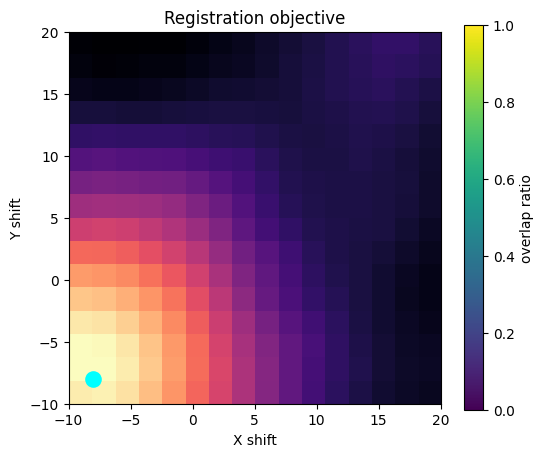

In [38]:
# The following is a faster version of registration, although the plotting is not included in this class.
IF_match_data_mtr= ifmatch.IFmatchMatrix(
    Calcium_imaging_df= df_clust,
    CGRP_raw= CGRP_raw,
    NF_raw= NF_raw,
    Calcium_height= shape[1],
    Calcium_width= shape[2])

best_shift, best_score= IF_match_data_mtr.Registration_optimize(
                                IF_threshold=2000,
                                a = 1.05,                  # fixed scale in X
                                c = 1.02,                  # fixed scale in Y
                                step = 2.0,
                                start_X = -10.0,
                                end_X = 20.0,
                                start_Y = -10.0,
                                end_Y = 20.0,
                                plot_result = True,
                                which_channel = 'NF')



In [ ]:
#One can see that the result is the same.

In [39]:
# Implementation of this registration can generate a new dataframe named df_IF_matrix that Output a dataframe of X and Y coordinates of calcium imaging and an additional column of IF intensities.
df_IF_matrix= IF_match_data_mtr.Merge_channels_in_df( a=1.05, b=best_shift[0], c=1.02, d=best_shift[1])


In [ ]:
# Take a 10 pixels to visualize the curves of calcium imaging which will be analyzed from now on.

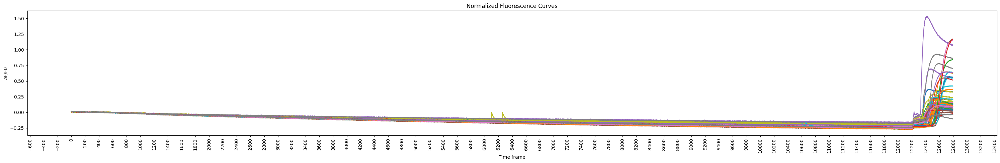

In [40]:
Sigdata= siganalysis.SigProcess(Cal,df)
Sigdata.Pre_curve_plot(temp_base_start=0, temp_base_end=900)


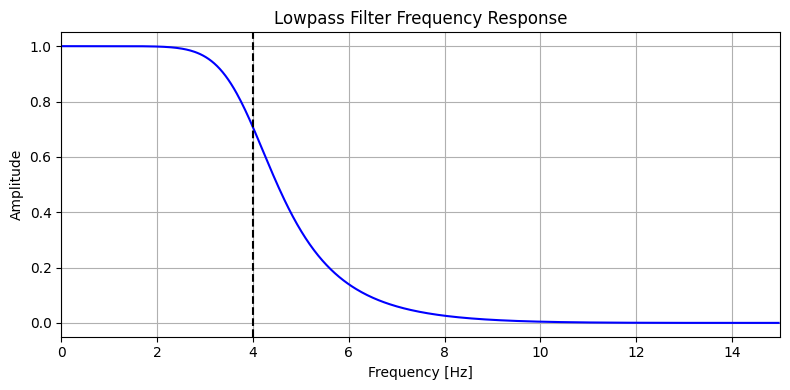

In [41]:
# Butter low pass filter to reduce the influence from high frequency noise. 
# First plot the frequency response.
Sigdata.Fre_response_plot(fs=30, order = 4, cutoff=4)

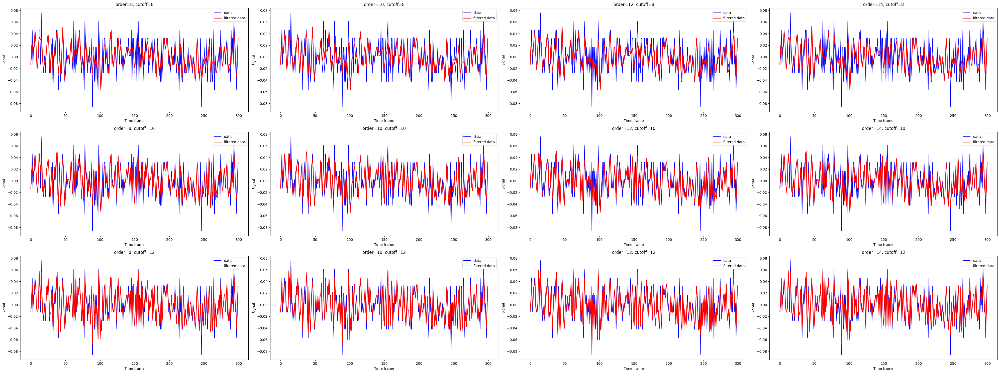

In [42]:
# To determine the cutoff and order of the butter filter, we can plot the effect of different combinations of cutoff and order. 
Sigdata.Butter_plot(
    fs=30, 
    pixel_index=1,
    time_start= 0, 
    time_end= 300,#choose the time frame window to plot the filter's effect
    cut_list= range(8,14,2), 
    order_list= (8,10,12,14),#list of values about cut and order to be plot and tested          
    def_base_start=0, 
    def_base_end=300,
    figsize= (10,5)    
    )

In [43]:
# Notice that the normalization is already done in the Butter_filter function. 
# If you want to use the filter, take the first output Cal_filt; if you don't want to use the filter, take the second Cal_unfilt which is also normalized
# Notice that def_base_start and def_base_end are used to define the baseline for normalization.
Cal_filt,Cal_unfilt= Sigdata.Butter_filter(fs=30, cutoff=12,  order=14,
                  def_base_start=0, def_base_end=12000)

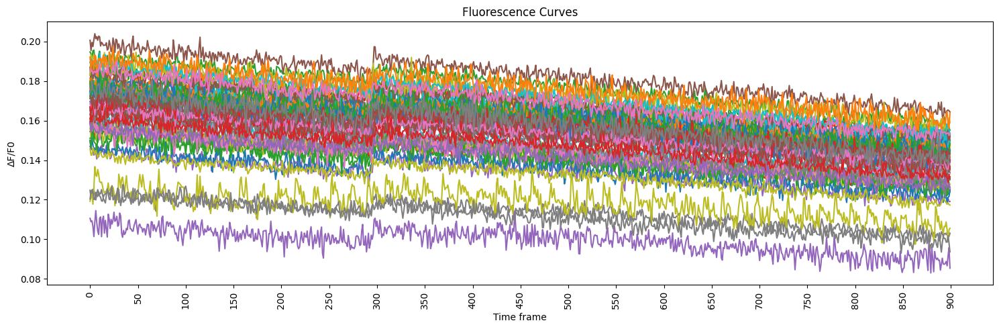

In [44]:
# A quality control plot for loop to see if the fiter is doing things right.
Sigdata.Curve_plot(Cal_filt,
                time_start= 0, time_end= 900,
                figsize= (15,5),
                x_interval= 50)

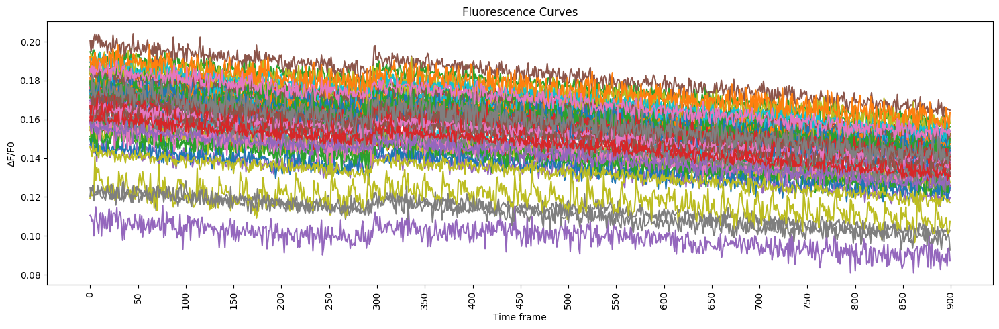

In [ ]:
# Show the original curve to compare
Sigdata.Curve_plot(Cal_unfilt,
                time_start= 0, time_end= 900,
                figsize= (15,5),
                x_interval= 50)

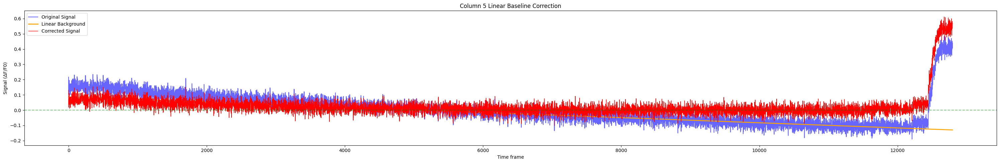

In [46]:
# Notice that if the calcium imaging is too long, the photobleaching effect is no longer linear. The solution is to fit on the window close to the time window that is analyzed as an example here, the stimulated response is analyzed at 12000's time frame, then the 6000-12000 window that is close to the 12000 is used to perform this correction"""
Sigdata= siganalysis.SigProcess(Cal,df)

# Pick one time series (in column) to visualize correction
Sigdata.Subtract_linear_pick_column_plot(
       Cal_filt, 
       linear_fit_start= 6000, 
       linear_fit_end= 12000,
       column_index=5, figsize=(30,5)
       )

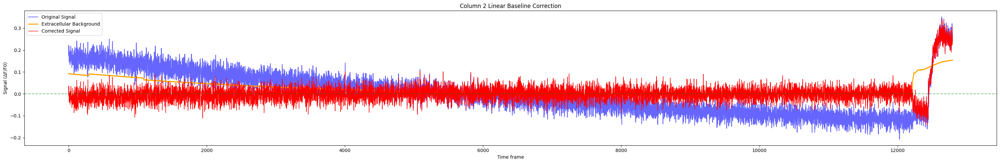

In [47]:
"""-----Linear correction + background removal
In addition to removing consistent linear change of the signal, it is also possible to remove non-linear changes due to non-linear changes in background. This refers to the whole image brightness changes when adding reagent during calcium imaging or neutrophile response. 
"""
# Calculate the background change in extracellular region.
# It averages over all background pixels and normalizes the curve.
extr_background= Sigdata.Extract_extr_base(
    Cal_background, 
    def_base_start= 6000,
    def_base_end= 12000)
# Visualize the effect of background removal following linear correction.
Sigdata.Subtract_background_plot(
                array= Cal_filt, 
                extr_background= extr_background,
                linear_fit_start= 6000, 
                linear_fit_end= 12000,
                column_index=2 #which pixel is drawn here
                )

In [ ]:
# By compared with linear correction without background correction, one can easily see that the peak height is decreased (from around 0.5 to 0.3), because the contribution from the background changes is subtracted.

In [48]:
# Implementation of the correction:
# Only perform linear subtraction of photobleaching effect
corrected_no_extrac, photobleach = Sigdata.Subtract_linear_baseline(
    Cal_filt, 
    linear_fit_start= 6000, 
    linear_fit_end= 12000
    )

# Perform linear subtraction and then background subtraction.
corrected, background = Sigdata.Extr_background_subtract(
                array= Cal_filt, 
                extr_background= extr_background,
                linear_fit_start= 6000, 
                linear_fit_end= 12000
                )

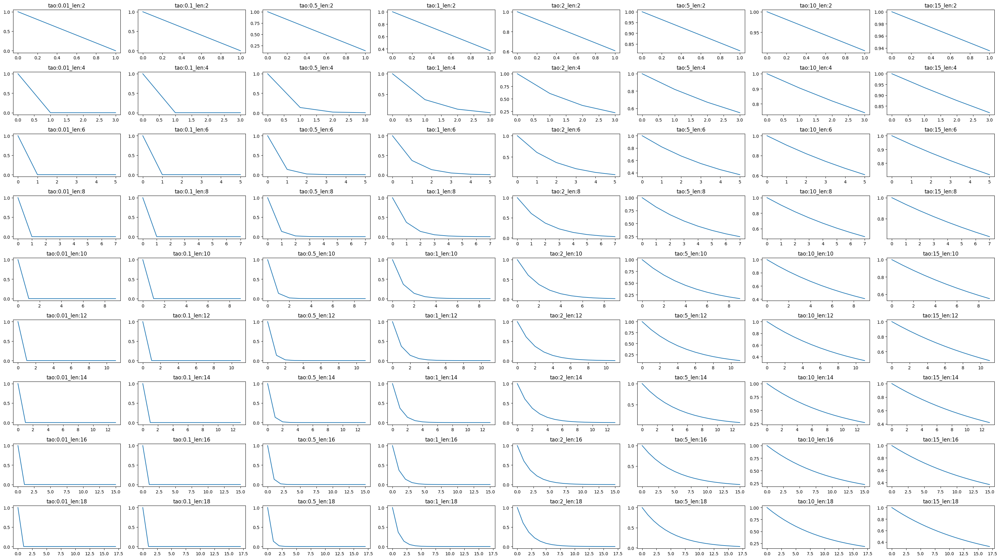

In [49]:
# Deconvolution for frequency-based analysis
Sigdata= siganalysis.SigProcess(corrected, df)

# Plot kernals. 
# When the calcium spike's shape is known, can make decision on the kernal's shape that is the closest to the calcium spike shape.
Sigdata.Kernels_plot(length_list=range(2,20,2), tao_list=(0.01,0.1,0.5,1,2,5,10,15),figsize=(4,2))

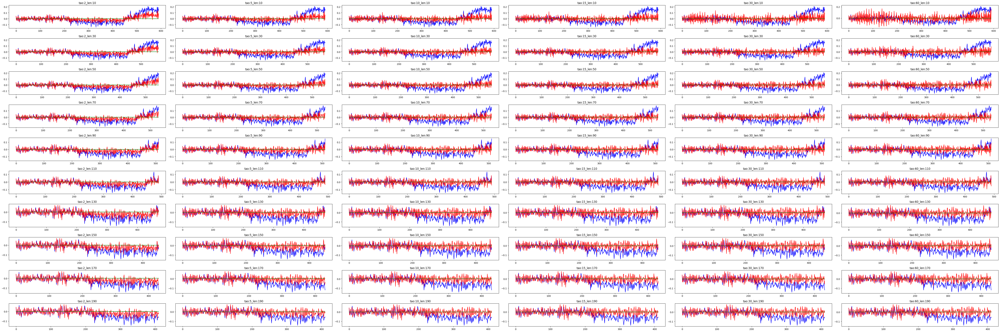

In [50]:
# When the calcium spike shape is unknown, can plot all the deconvolution results to see which kernel make more sense.
Sigdata.Decon_para_plot(array= corrected[12000:12600,:], column_index=0,
                        length_list= range(10,200,20), tao_list=(2,5,10,15,30,60), 
                        figsize=(10,2))


In [51]:
# Implementation:
# This function is very slow to run for the whole time series.pick a time window [12000:12600,:] instead.
Cal_decon= Sigdata.Decon(corrected[12000:12600,:], length= 10, tao= 30)

In [52]:
# This is a faster version that if long time period has to be deconvolved.
Cal_decon_fast= Sigdata.Decon_fast(corrected, length= 10, tao= 30)


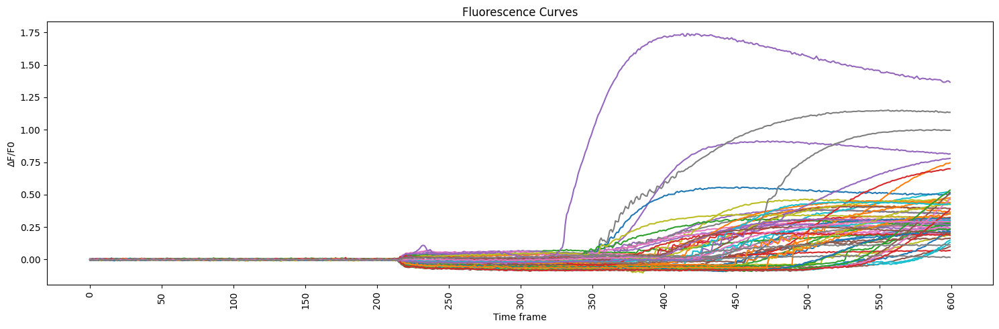

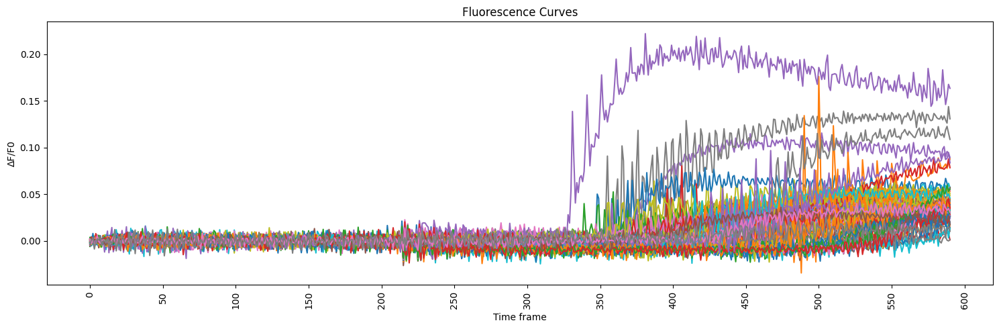

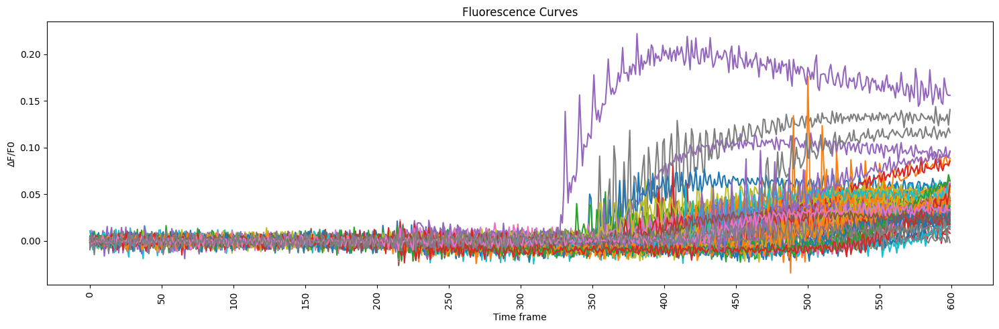

In [53]:
# The following plot shows the effect of deconvolution. Also it can be seen that Sigdata.Decon and Sigdata.Decon_fast generate the same output.
Sigdata.Curve_plot(corrected,
                time_start= 12000, time_end=12600,
                figsize= (15,5),
                x_interval= 50)

Sigdata.Curve_plot(Cal_decon,
                time_start= 0, time_end=600,
                figsize= (15,5),
                x_interval= 50)

Sigdata.Curve_plot(Cal_decon_fast,
                time_start= 12000, time_end= 12600,
                figsize= (15,5),
                x_interval= 50)


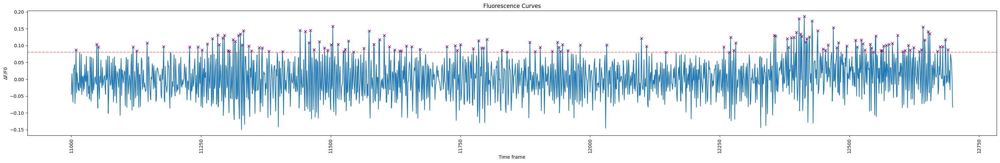

In [54]:
"""
----Signal quantification-----------
Plot a curve to define spike sorting cutoff

Note: Since photobleaching correction is performed within the time window 11000:12600, frequency analysis should be restricted to this interval or at least remain close to it. Analyzing outside this range may introduce artifacts due to baseline drift in long calcium imaging time series.
"""
Sig_quant= siganalysis.Sigquanti(Cal_decon_fast, df, shape[1], shape[2])
Sig_quant.Get_spike_plot(pixel_index= 5006,
                         spike_h_cutoff=0.08,
                         time_start= 11000, time_end= 12700, #which time window to show
                         figsize= (30,5) )

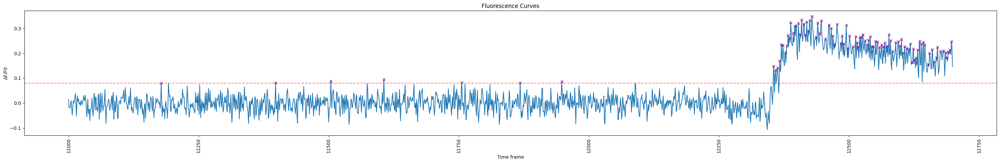

In [55]:
# Doing it in the non-deconvoluted cureve
Sig_quant= siganalysis.Sigquanti(corrected, df, shape[1], shape[2])
Sig_quant.Get_spike_plot(pixel_index= 5006,
                         spike_h_cutoff=0.08,
                         time_start= 11000, time_end= 12700, #which time window to show
                         figsize= (30,5) )

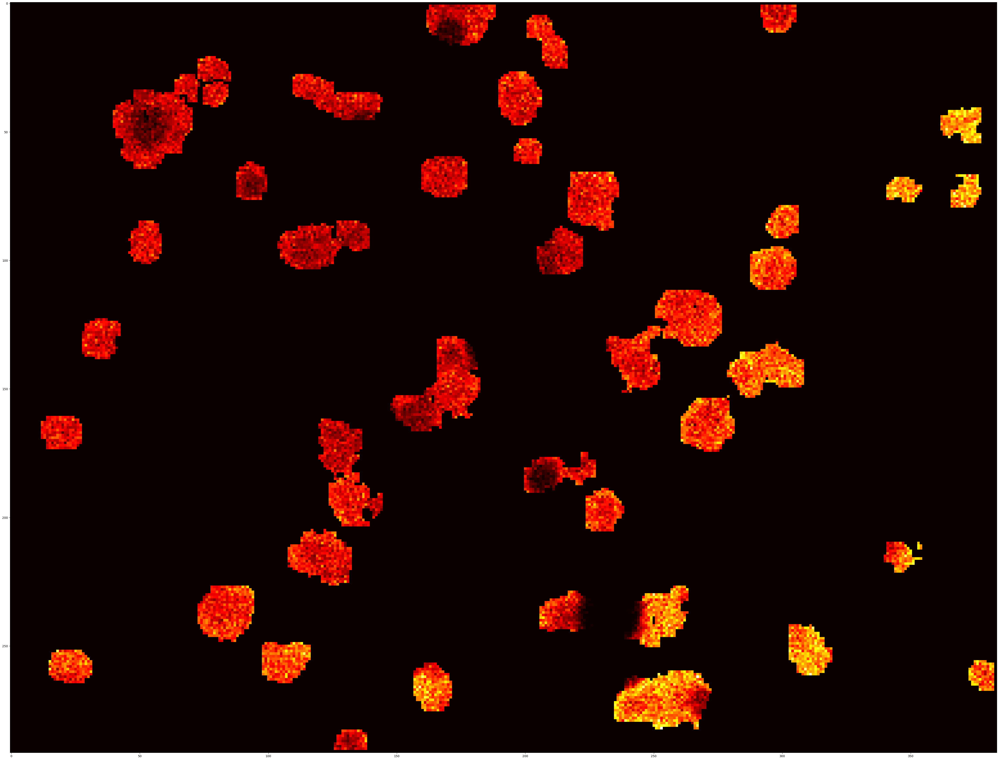

In [56]:
"""
----Plot spiking rate and peak height heatmap-----
Also very useful in defining spike_h_cutoff.
"""
Sig_quant= siganalysis.Sigquanti(Cal_decon_fast, df_IF_matrix, shape[1], shape[2])
Sig_quant.Freq_heatmap(spike_h_cutoff= 0.08, #peak height cutoff used to define calcium spikes
                          seg_start= 10000, seg_end= 11000, #pick a time window to calculate spike frequency
                          fs= 28.57 #sample frequency of calcium imaging, useful for spike frequency to be in Hz
                          )

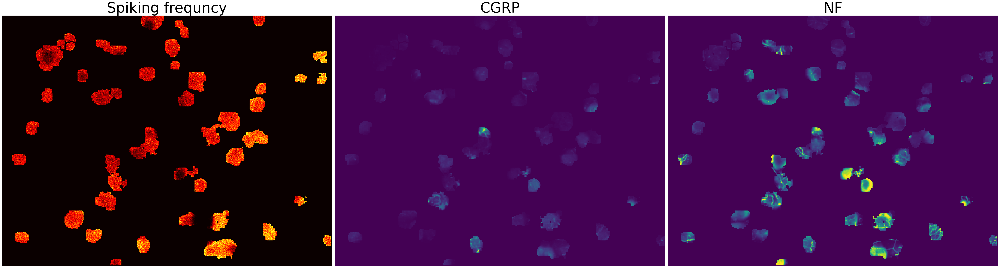

In [57]:
# Plot to check which IF marker positive neurons have larger spiking frequency. Make sure that the input df_clust have columns of IF staining value. These values are added in the IFmatch or IFmatchMatrix class"""
Sig_quant= siganalysis.Sigquanti(Cal_decon_fast, df_IF_matrix, shape[1], shape[2])
Sig_quant.IF_freq_heatmap(spike_h_cutoff= 0.08, #peak height cutoff used to define calcium spikes
                          seg_start= 10000, seg_end= 11000, #pick a time window to calculate spike frequency
                          fs= 28.57 #sample frequency of calcium imaging, useful for spike frequency to be in Hz
                          )

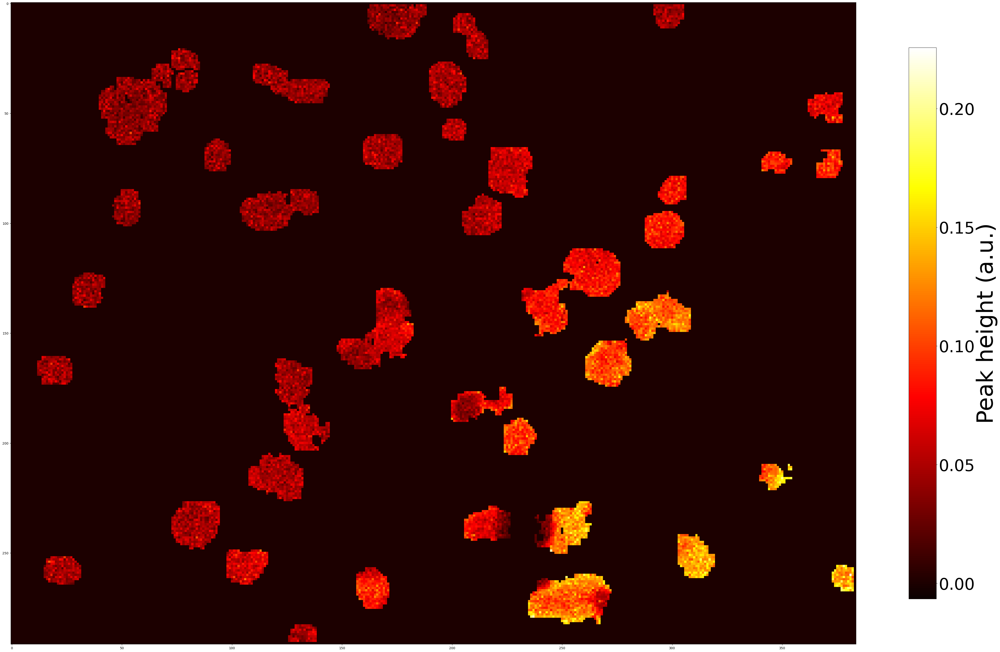

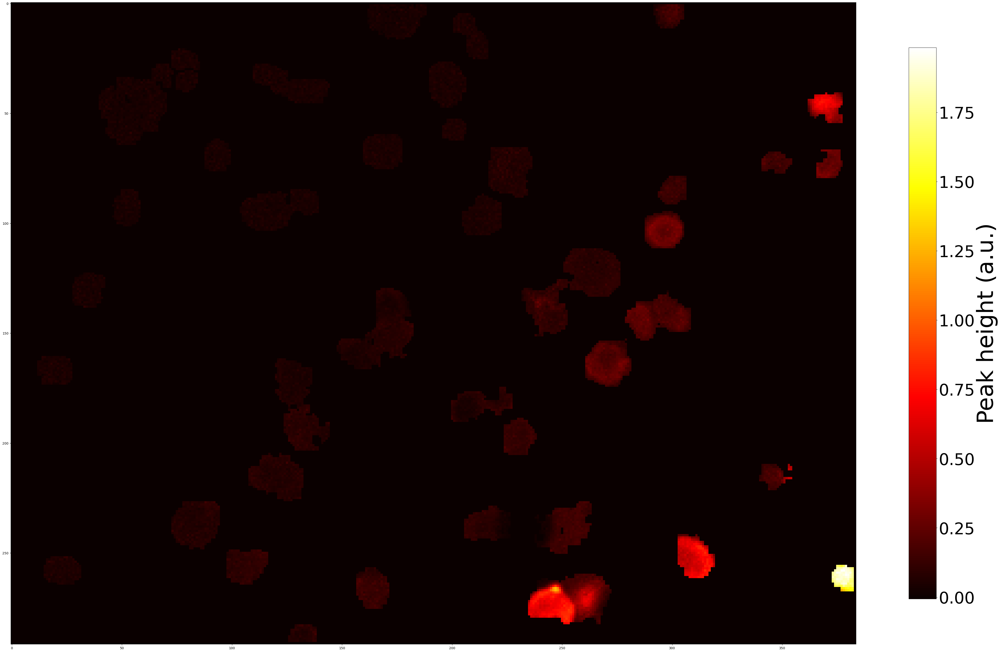

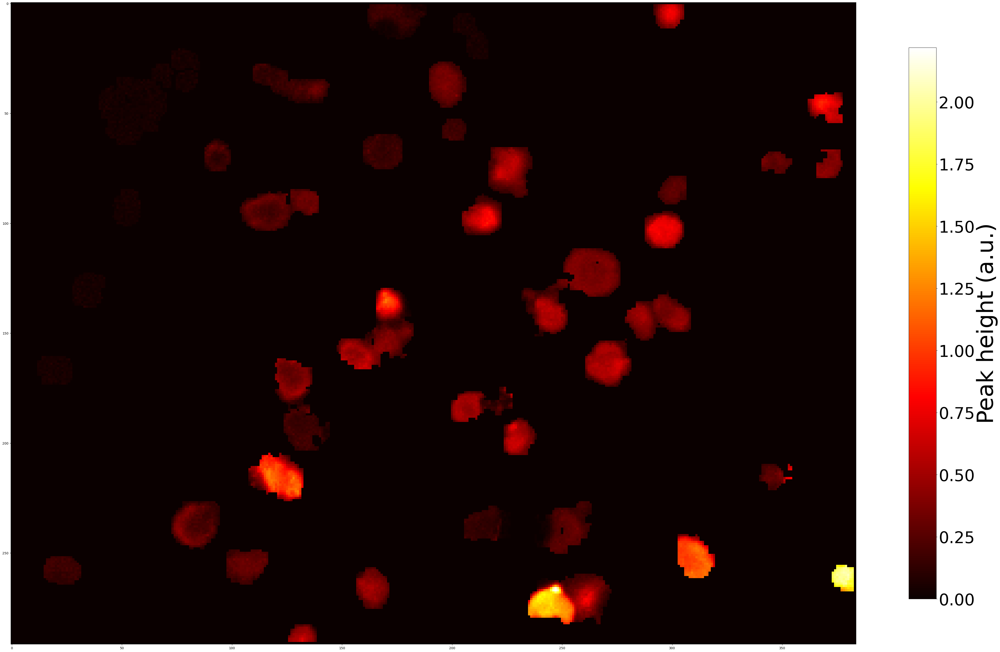

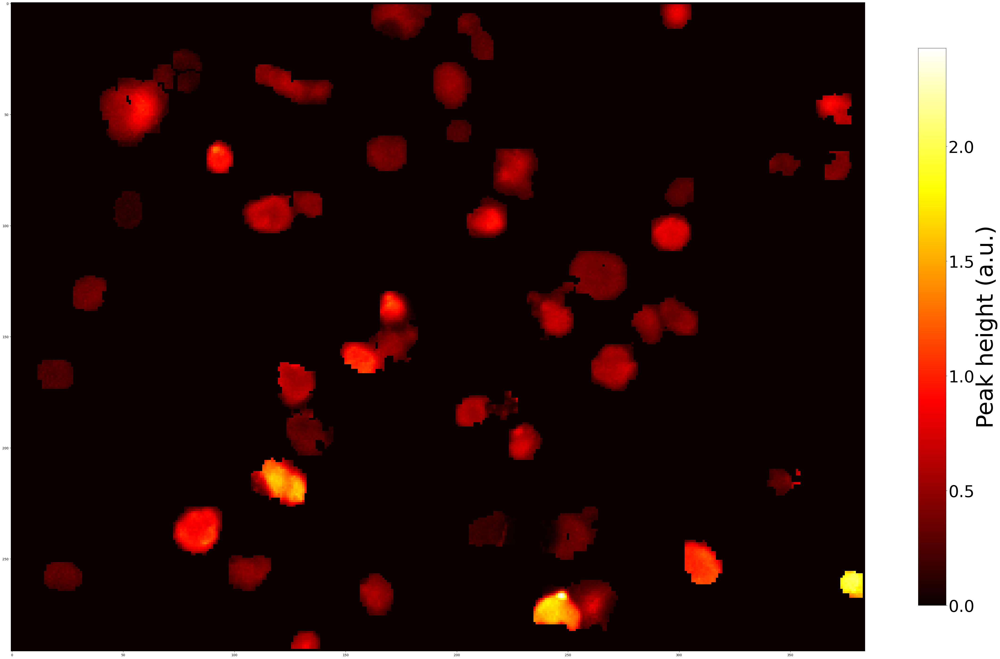

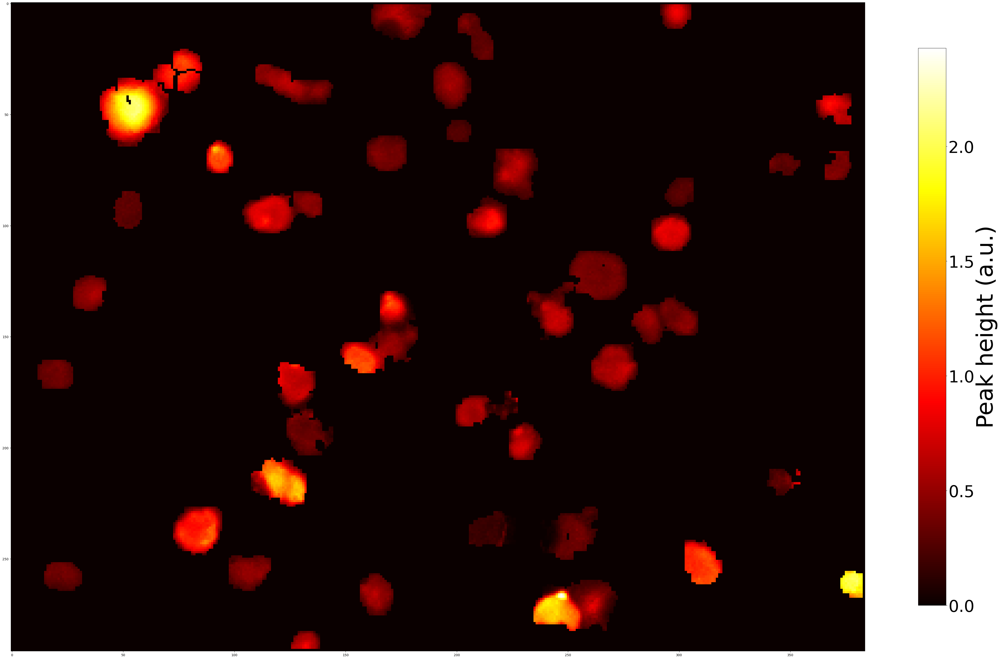

In [58]:
# Peak height based analysis
# Notice that the input is not deconvoluted curves
# Also check the heatmap first, before implementation
Sig_quant= siganalysis.Sigquanti(corrected, df_IF_matrix, shape[1], shape[2])
Sig_quant.Peak_height_heatmap(base_start= 11800, base_end=12200,
                  sti_start=12200, sti_end=12300)

Sig_quant= siganalysis.Sigquanti(corrected, df_IF_matrix, shape[1], shape[2])
Sig_quant.Peak_height_heatmap(base_start= 11800, base_end=12200,
                  sti_start=12200, sti_end=12400)

Sig_quant= siganalysis.Sigquanti(corrected, df_IF_matrix, shape[1], shape[2])
Sig_quant.Peak_height_heatmap(base_start= 11800, base_end=12200,
                  sti_start=12200, sti_end=12500)

Sig_quant= siganalysis.Sigquanti(corrected, df_IF_matrix, shape[1], shape[2])
Sig_quant.Peak_height_heatmap(base_start= 11800, base_end=12200,
                  sti_start=12200, sti_end=12600)

Sig_quant= siganalysis.Sigquanti(corrected, df_IF_matrix, shape[1], shape[2])
Sig_quant.Peak_height_heatmap(base_start= 11800, base_end=12200,
                  sti_start=12200, sti_end=12700)


In [59]:
# Implementation of the calcium quantification
# Output spiking rate and peak height data
output_df= df_IF_matrix.copy()

Sig_quant= siganalysis.Sigquanti(Cal_decon_fast, df_IF_matrix, shape[1], shape[2])
output_df=Sig_quant.Freq_data_output( output_df,
                  colname='Freq_10k-11k',#how do you call this data? e.g., spikeing rate (Hz))
                  spike_h_cutoff=0.08, #peak height cutoff used to define calcium spikes
                  seg_start=10000, seg_end=11000, #pick a time window to calculate spike frequency
                  fs= 28.57)


In [60]:
output_df.head()

,X,Y,Cluster,NF,CGRP,Freq_10k-11k
0,163,1,0,6004,768,0.91424
1,164,1,0,5560,809,0.42855
2,165,1,0,4545,881,0.62854
3,166,1,0,4344,722,0.65711
4,167,1,0,4428,803,0.94281


In [61]:
output_df=Sig_quant.Peak_height_output( output_df,
                  colname='PH_10k-11k',#how do you call this data? e.g., spikeing rate (Hz))
                  base_start= 11800, base_end=12200,
                  sti_start=12200, sti_end=12700)
output_df.head()

,X,Y,Cluster,NF,CGRP,Freq_10k-11k,PH_10k-11k
0,163,1,0,6004,768,0.91424,0.146563
1,164,1,0,5560,809,0.42855,0.150437
2,165,1,0,4545,881,0.62854,0.169716
3,166,1,0,4344,722,0.65711,0.187659
4,167,1,0,4428,803,0.94281,0.165824


In [62]:
# Aggregate DataFrame from pixel level to neuron level
df_aggre= output_df.groupby("Cluster").agg(
    freq_mean=("Freq_10k-11k", "mean"),
    freq_median=("Freq_10k-11k", "median"),
    peak_mean=("PH_10k-11k", "mean"),
    peak_max=("PH_10k-11k", "max"),
    n_pixels=("Cluster", "size"))

df_aggre.head()

,freq_mean,freq_median,peak_mean,peak_max,n_pixels
Cluster,,,,,
0,0.723746,0.74282,0.152353,0.246047,346
1,0.774716,0.77139,0.161492,0.238793,189
2,0.851585,0.85710,0.157393,0.233331,259
3,1.049536,1.02852,0.176974,0.294103,382
4,1.334770,1.34279,0.200500,0.315236,399
